# B 생존분석 · 정체 경보: 특보가 뜨면 몇 시간 만에 막히나, 미리 알릴 수 있나

담당: B · 노션 분석 설계 **9.2 ③ · 11.1 (1)** (Q5 "몇 시간 전에 미리 알 수 있나"의 한 부분)

| 항목 | 정의 |
|---|---|
| 출발 (t = 0) | 서울 대설 · 호우특보 발효 시각 (`weather_warnings`의 `effective_start`, 끝 시각 기준 시간) |
| 사건 | 도로 · 방향이 처음 **정체**(`is_congested = 1`: 평소의 2/3 속도 미만 링크가 도로 길이의 30% 이상)가 된 시간 |
| 지켜보는 시간 | 12시간 (t = 1 ~ 12). 12시간 안에 안 막히면 "12시간 동안 안 막혔다"로 **중도 절단** |
| 이미 막혀 있던 도로 | t = 0에 이미 정체면 '특보 뒤에 막힌 것'이 아니므로 뺀다 (몇 개인지 적는다) |
| 대조군 | 같은 시즌 · 같은 요일 유형 · 같은 시각에 시작하는 **12시간 내내 맑은** 날 (특보 날과 가장 가까운 날) |

- 정체는 24시간 표(`road_hourly_24h`, 요일 유형 · 시간마다 평소값)로 판정하므로, 평소의 출퇴근 정체는 정체로 세지 않는다.
- Kaplan-Meier: 특보 vs 대조, 도로 유형별. Cox: 특보의 위험비, 특보 안에서 도로 유형 · 주말 · 곧 출퇴근 · 강수 · 적설 효과. 같은 특보의 도로끼리는 독립이 아니라서 **특보 단위로 묶은 표준오차**(`cluster_col`)를 쓴다.
- Train + Dev(학습 3년)만 본다. Test는 마지막 평가 때 `OPEN_TEST = True`로.
- 입력은 `ljh_comparison`과 같은 `data/derived/topis_weather/road_hourly_24h_train_dev_v01.parquet` (`python src/analysis/hourly_24h.py`).

In [1]:
import sys
from pathlib import Path
def find_project_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'README.md').is_file() and (candidate / '.git').exists():
            return candidate
    raise FileNotFoundError('프로젝트 루트를 찾지 못했습니다.')

ROOT = find_project_root()
OPEN_TEST = False   # True: 마지막 평가 때만 Test 시즌 특보도 넣는다
HORIZON = 12        # 특보 뒤 지켜보는 시간
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test
from src.io_utils import add_model_set, load_processed
from src.analysis import hourly_24h as H

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
FIG = ROOT / 'outputs' / 'figures' / 'ljh'; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / 'outputs' / 'tables'
pd.set_option('display.width', 160)

## 1. 읽기: 24시간 도로 표 · 특보 구간

In [2]:
parts = [pd.read_parquet(H.out_path('train_dev'))]
if OPEN_TEST:
    parts.append(pd.read_parquet(H.out_path('holdout')))
h = add_model_set(pd.concat(parts, ignore_index=True), include_test=OPEN_TEST)
h['datetime'] = pd.to_datetime(h['datetime'])
w = load_processed('weather_hourly', include_test=OPEN_TEST)[['datetime', 'precip_mm', 'new_snow_3h_cm', 'temp_c']]
w['datetime'] = pd.to_datetime(w['datetime'])

warn = load_processed('weather_warnings', include_test=OPEN_TEST)
warn = warn[warn['kind'].isin(['snow', 'rain'])].copy()
warn['effective_start'] = pd.to_datetime(warn['effective_start'])
in_grid = set(h['datetime'].unique())
warn['in_period'] = warn['effective_start'].isin(in_grid)
print('특보(대설 · 호우):', len(warn), '건 → 연구 기간 · 공휴일 아닌 날', int(warn['in_period'].sum()), '건')
warn = warn[warn['in_period']].reset_index(drop=True)
warn['warn_id'] = np.arange(len(warn))
warn['kind_name'] = warn['kind'].map({'snow': '대설', 'rain': '호우'})
warn.groupby(['model_set', 'kind_name']).size().unstack(fill_value=0)

특보(대설 · 호우): 56 건 → 연구 기간 · 공휴일 아닌 날 51 건


kind_name,대설,호우
model_set,,
dev,5,12
train,9,25


## 2. 대조 시작점: 같은 시즌 · 요일 유형 · 시각에 12시간 내내 맑은 날

In [3]:
grp = h.drop_duplicates('datetime').set_index('datetime')[['season', 'daytype', 'weather_group']].sort_index()
clear = grp['weather_group'].eq('맑음')
# 앞으로 HORIZON 시간이 모두 맑은 시작점 (빈 시간이 있으면 맑음이 아닌 것으로)
full = clear.reindex(pd.date_range(grp.index.min(), grp.index.max() + pd.Timedelta(HORIZON, unit='h'), freq='h'), fill_value=False)
all_clear = full.astype(int)[::-1].rolling(HORIZON + 1, min_periods=HORIZON + 1).sum()[::-1].eq(HORIZON + 1)
warn_hours = set()
for _, r in warn.iterrows():
    warn_hours.update(pd.date_range(r['effective_start'] - pd.Timedelta(HORIZON, unit='h'), r['effective_start'] + pd.Timedelta(HORIZON, unit='h'), freq='h'))
ok_start = grp.index[all_clear.reindex(grp.index).fillna(False).to_numpy()]
ok_start = [t for t in ok_start if t not in warn_hours]
cand = grp.loc[ok_start].reset_index()

ctrl = []
for _, r in warn.iterrows():
    t0 = r['effective_start']
    c = cand[(cand['season'] == grp.at[t0, 'season']) & (cand['daytype'] == grp.at[t0, 'daytype'])
             & (cand['datetime'].dt.hour == t0.hour)]
    if len(c):
        best = c.iloc[(c['datetime'] - t0).abs().argsort().iloc[0]]
        ctrl.append({'warn_id': r['warn_id'], 'control_start': best['datetime'], 'days_apart': (best['datetime'] - t0).days})
ctrl = pd.DataFrame(ctrl)
print(f"대조 시작점을 찾은 특보 {len(ctrl)}/{len(warn)}건 · 떨어진 날 수 중앙값 {ctrl['days_apart'].abs().median():.0f}일")
ctrl.head()

대조 시작점을 찾은 특보 51/51건 · 떨어진 날 수 중앙값 1일


,warn_id,control_start,days_apart
0,0,2022-12-14 09:00:00,-1
1,1,2022-12-22 05:00:00,1
2,2,2023-01-05 23:00:00,-1
3,3,2023-01-25 04:00:00,-1
4,4,2023-06-28 09:00:00,-1


## 3. 생존 자료 만들기 (특보 × 도로 · 방향)

In [4]:
cong = h.set_index(['datetime', 'road_id', 'direction'])['is_congested']
roads = h[['road_id', 'road_name', 'direction', 'function_type']].drop_duplicates()

def survival_rows(starts):
    # starts: warn_id · start 열. 시작 · 도로마다 처음 정체까지 시간 (HORIZON 안 막히면 중도 절단)
    grid = starts.assign(k=[list(range(HORIZON + 1))] * len(starts)).explode('k')
    grid['k'] = grid['k'].astype(int)
    grid['datetime'] = grid['start'] + pd.to_timedelta(grid['k'], unit='h')
    g = grid.merge(roads, how='cross')
    g['cong'] = cong.reindex(pd.MultiIndex.from_frame(g[['datetime', 'road_id', 'direction']])).to_numpy()
    g = g.dropna(subset=['cong'])
    keys = ['warn_id', 'road_id', 'direction']
    pre = g[g['k'] == 0].set_index(keys)['cong']
    after = g[g['k'] >= 1]
    first = after[after['cong'] == 1].groupby(keys)['k'].min()
    last = after.groupby(keys)['k'].max()
    s = pd.DataFrame({'pre': pre}).join(first.rename('first'), how='outer').join(last.rename('last'), how='outer').reset_index()
    s = s.dropna(subset=['last'])
    s['already'] = s['pre'].eq(1)
    s['event'] = s['first'].notna().astype(int)
    s['duration'] = s['first'].fillna(s['last']).astype(int)
    return s.merge(roads, on=['road_id', 'direction'])

sw = survival_rows(warn[['warn_id', 'effective_start']].rename(columns={'effective_start': 'start'}))
sc = survival_rows(ctrl.rename(columns={'control_start': 'start'})[['warn_id', 'start']])
sw['group'], sc['group'] = '특보', '맑은 날(대조)'
surv = pd.concat([sw, sc], ignore_index=True).merge(
    warn[['warn_id', 'kind', 'kind_name', 'max_level', 'effective_start', 'model_set', 'season']], on='warn_id')
print('t = 0에 이미 정체라 뺀 행:', surv.groupby('group')['already'].sum().to_dict())
surv = surv[~surv['already']].copy()
summary = surv.groupby(['kind_name', 'group']).agg(특보=('warn_id', 'nunique'), 도로행=('event', 'size'),
                                                  막힘=('event', 'sum'), 막힌비율=('event', 'mean'))
summary.round(3)

t = 0에 이미 정체라 뺀 행: {'맑은 날(대조)': 109, '특보': 147}


특보   도로행   막힘   막힌비율
kind_name group                         
대설        맑은 날(대조)  14  2473  126  0.051
          특보        14  2486  245  0.099
호우        맑은 날(대조)  37  6573  395  0.060
          특보        37  6523  986  0.151

## 4. Kaplan-Meier: 특보 뒤 '아직 안 막힌' 비율

,특보,집단,3시간 안 막힘,6시간,12시간,도로행
0,대설,맑은 날(대조),0.013,0.028,0.051,2473
1,대설,특보,0.059,0.082,0.099,2486
2,호우,맑은 날(대조),0.019,0.035,0.060,6573
3,호우,특보,0.084,0.124,0.152,6523


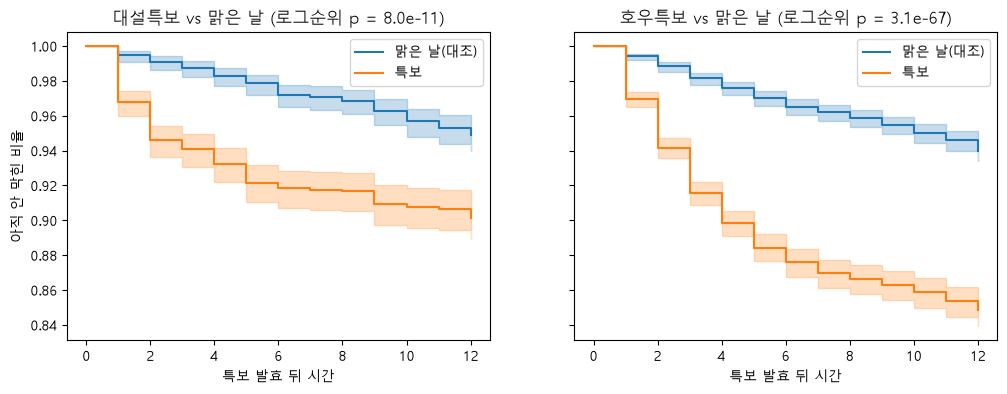

In [5]:
def cum_at(kmf, t):
    return 1 - float(kmf.survival_function_at_times(t).iloc[0])

rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, kind in zip(axes, ['대설', '호우']):
    sub = surv[surv['kind_name'] == kind]
    for gname, g in sub.groupby('group'):
        kmf = KaplanMeierFitter().fit(g['duration'], g['event'], label=gname)
        kmf.plot_survival_function(ax=ax, ci_show=True)
        rows.append({'특보': kind, '집단': gname, '3시간 안 막힘': cum_at(kmf, 3), '6시간': cum_at(kmf, 6),
                     '12시간': cum_at(kmf, 12), '도로행': len(g)})
    a, b = sub[sub['group'] == '특보'], sub[sub['group'] != '특보']
    p = logrank_test(a['duration'], b['duration'], a['event'], b['event']).p_value
    ax.set_title(f'{kind}특보 vs 맑은 날 (로그순위 p = {p:.1e})'); ax.set_xlabel('특보 발효 뒤 시간'); ax.set_ylabel('아직 안 막힌 비율')
    ax.set_xticks(range(0, HORIZON + 1, 2))
fig.savefig(FIG / 'survival_km_warning_vs_clear.png', dpi=150, bbox_inches='tight')
km_tab = pd.DataFrame(rows)
km_tab.to_csv(TAB / 'ljh_survival_km.csv', index=False, encoding='utf-8-sig')
km_tab.round(3)

,특보,도로 유형,3시간,6시간,12시간,도로행
0,대설,도시고속도로,0.122,0.188,0.230,287
1,대설,주간선도로,0.051,0.068,0.081,2199
2,호우,도시고속도로,0.232,0.305,0.362,737
3,호우,주간선도로,0.066,0.101,0.125,5786


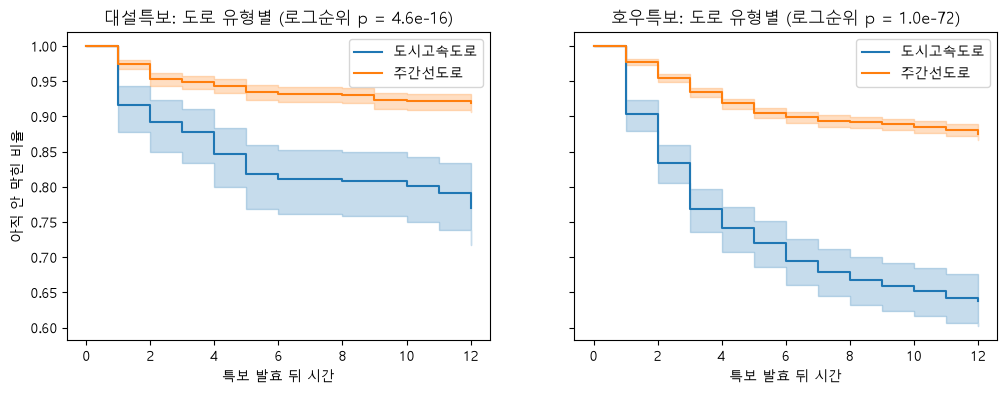

In [6]:
# 특보 안에서 도로 유형별
rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, kind in zip(axes, ['대설', '호우']):
    sub = surv[(surv['kind_name'] == kind) & (surv['group'] == '특보')]
    for ft, g in sub.groupby('function_type'):
        kmf = KaplanMeierFitter().fit(g['duration'], g['event'], label=ft)
        kmf.plot_survival_function(ax=ax)
        rows.append({'특보': kind, '도로 유형': ft, '3시간': cum_at(kmf, 3), '6시간': cum_at(kmf, 6), '12시간': cum_at(kmf, 12),
                     '도로행': len(g)})
    a, b = sub[sub['function_type'] == '도시고속도로'], sub[sub['function_type'] != '도시고속도로']
    p = logrank_test(a['duration'], b['duration'], a['event'], b['event']).p_value
    ax.set_title(f'{kind}특보: 도로 유형별 (로그순위 p = {p:.1e})'); ax.set_xlabel('특보 발효 뒤 시간'); ax.set_ylabel('아직 안 막힌 비율')
fig.savefig(FIG / 'survival_km_function_type.png', dpi=150, bbox_inches='tight')
pd.DataFrame(rows).round(3)

## 5. Cox 비례위험

(1) **특보의 위험비**: 특보 시작 vs 맑은 날 시작, 특보 종류로 층을 나눈다 (`strata`).
(2) **특보 안에서 무엇이 빨리 막히게 하나**: 공변량은 **특보 발효 시각까지 알 수 있는 값만** 쓴다. 날씨는 발효 직전 3시간(t−3, t]의 관측이다.
특보 뒤 3시간 값을 쓰면 '앞으로 올 비 · 눈'을 미리 아는 셈이라, 경보에 쓸 수 있는 결과가 아니다.
대설특보는 14건뿐이라 변수를 3개(도시고속도로 · 곧 평일 출퇴근 · 직전 3시간 신적설)로 줄였다. 변수가 많으면 특보 수에 비해 추정이 불안정해진다.
(3) **비례위험 가정 검사**: Cox는 '위험비가 시간에 따라 변하지 않는다'고 가정한다. 순위 시간 변환 검정(`proportional_hazard_test`)에서 p < 0.05면 가정이 깨진 것이다.
깨진 변수가 있으면 **0~3시간 / 3시간 이후**로 나눠 구간마다 위험비를 다시 낸다.
위험비 > 1이면 더 빨리 막힌다. 표준오차는 모두 특보 단위로 묶는다.

In [7]:
from lifelines.statistics import proportional_hazard_test
SPLIT_H = 3

def fit_cox(d, cov, strata=None, penalizer=0.01):
    # 변수가 여럿인 특보 안 모델은 약한 벌점(0.01)으로 추정을 안정시킨다. 특보 하나만 보는 모델은 벌점 없이
    cols = ['duration', 'event', 'cluster'] + cov + ([strata] if strata else [])
    return CoxPHFitter(penalizer=penalizer).fit(d[cols], 'duration', 'event', cluster_col='cluster',
                                           strata=[strata] if strata else None)

def ph_check(m, d):
    # 순위 시간 변환 검정. 표는 변수마다 p
    t = proportional_hazard_test(m, d, time_transform='rank').summary
    return t['p'].rename('비례위험 p')

def piecewise(d, cov, strata=None, penalizer=0.01):
    # 0~3시간: 3시간에서 중도 절단 / 3시간 이후: 3시간까지 안 막힌 행만, 3시간을 빼고 다시 센다
    early = d.assign(event=(d['event'].eq(1) & d['duration'].le(SPLIT_H)).astype(int), duration=d['duration'].clip(upper=SPLIT_H))
    late = d[d['duration'] > SPLIT_H].assign(duration=lambda x: x['duration'] - SPLIT_H)
    out = []
    for name, part in [(f'0~{SPLIT_H}시간', early), (f'{SPLIT_H}시간 이후', late)]:
        m = fit_cox(part, cov, strata, penalizer)
        s = m.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']].copy()
        s.insert(0, '구간', name)
        out.append(s)
    return pd.concat(out)

surv['warning'] = surv['group'].eq('특보').astype(int)
surv['cluster'] = surv['warn_id']
cph = fit_cox(surv, ['warning'], strata='kind', penalizer=0.0)
hr_warning = cph.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']]
ph_w = ph_check(cph, surv[['duration', 'event', 'cluster', 'warning', 'kind']])
display(hr_warning.join(ph_w))
hr_warning_pw = piecewise(surv, ['warning'], strata='kind', penalizer=0.0) if (ph_w < 0.05).any() else None
hr_warning_pw

,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p,비례위험 p
covariate,,,,,
warning,2.530154,1.882028,3.401479,7.843903e-10,0.000189


,구간,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,,
warning,0~3시간,4.740199,3.283877,6.842367,9.650415e-17
warning,3시간 이후,1.595197,1.184973,2.147436,2.077437e-03


In [8]:
# 특보 안 공변량: 발효 시각까지 알 수 있는 값만
ws = surv[surv['group'] == '특보'].copy()
start = ws['effective_start']
ws['expressway'] = ws['function_type'].eq('도시고속도로').astype(int)
ws['weekend'] = start.dt.dayofweek.ge(5).astype(int)
commute = {8, 9, 18, 19, 20}
# 달력으로 미리 아는 값: 발효 뒤 3시간 안에 평일 출퇴근 시간이 오는가
ws['commute_3h'] = [int(t.dayofweek < 5 and any(((t + pd.Timedelta(k, unit='h')).hour in commute) for k in (1, 2, 3))) for t in start]
ws['level_warning'] = ws['max_level'].ge(2).astype(int)
prev = []
for t in warn['effective_start']:
    win = w[(w['datetime'] > t - pd.Timedelta(3, unit='h')) & (w['datetime'] <= t)]   # 끝 시각 기준 t−2 · t−1 · t 시
    prev.append({'effective_start': t, 'precip_prev3h': win['precip_mm'].sum(), 'snow_prev3h': win['new_snow_3h_cm'].max()})
ws = ws.merge(pd.DataFrame(prev).drop_duplicates('effective_start'), on='effective_start', how='left')

COV = {'호우': ['expressway', 'weekend', 'commute_3h', 'precip_prev3h'],
       '대설': ['expressway', 'commute_3h', 'snow_prev3h']}
NAMES = {'expressway': '도시고속도로', 'weekend': '주말', 'commute_3h': '3시간 안에 평일 출퇴근', 'level_warning': '경보 단계',
         'precip_prev3h': '발효 직전 3시간 강수(mm)', 'snow_prev3h': '발효 직전 3시간 신적설(cm)'}
cox_rows, pw_rows = [], []
for kind, cov in COV.items():
    d = ws[ws['kind_name'] == kind][['duration', 'event', 'cluster'] + cov].dropna()
    cov = [c for c in cov if d[c].nunique() > 1]
    m = fit_cox(d, cov)
    s = m.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']].join(ph_check(m, d[['duration', 'event', 'cluster'] + cov]))
    s = s.rename(index=NAMES)
    s.insert(0, '특보', kind); s.insert(1, '구간', '전체 12시간')
    cox_rows.append(s)
    broken = s.index[s['비례위험 p'] < 0.05].tolist()
    print(kind, f"특보 {d['cluster'].nunique()}건 · 도로행 {len(d):,} · 막힘 {int(d['event'].sum())} · C-index {m.concordance_index_:.3f}"
          f" · 비례위험 깨진 변수: {broken or '없음'}")
    if broken:
        pw = piecewise(d, cov).rename(index=NAMES)
        pw.insert(0, '특보', kind)
        pw_rows.append(pw)
cox_tab = pd.concat(cox_rows + pw_rows)
cox_tab.to_csv(TAB / 'ljh_survival_cox.csv', encoding='utf-8-sig')
cox_tab.round(3)

호우 특보 37건 · 도로행 6,523 · 막힘 986 · C-index 0.719 · 비례위험 깨진 변수: ['발효 직전 3시간 강수(mm)']


대설 특보 14건 · 도로행 2,486 · 막힘 245 · C-index 0.780 · 비례위험 깨진 변수: 없음


,특보,구간,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p,비례위험 p
covariate,,,,,,,
도시고속도로,호우,전체 12시간,3.460,2.854,4.193,0.000,0.189
주말,호우,전체 12시간,0.285,0.182,0.446,0.000,0.350
3시간 안에 평일 출퇴근,호우,전체 12시간,1.699,1.075,2.685,0.023,0.872
발효 직전 3시간 강수(mm),호우,전체 12시간,1.015,1.003,1.027,0.012,0.046
도시고속도로,대설,전체 12시간,2.947,1.785,4.865,0.000,0.801
3시간 안에 평일 출퇴근,대설,전체 12시간,4.987,1.259,19.760,0.022,0.315
발효 직전 3시간 신적설(cm),대설,전체 12시간,0.969,0.833,1.127,0.681,0.310
도시고속도로,호우,0~3시간,3.738,2.647,5.280,0.000,NaN
주말,호우,0~3시간,0.318,0.190,0.532,0.000,NaN


## 6. 특보별로 보기: 몇 개 도로가 몇 시간 만에 막혔나

In [9]:
per = (ws.groupby(['warn_id', 'kind_name', 'effective_start', 'max_level'])
         .apply(lambda g: pd.Series({'도로행': len(g), '12시간 안 막힘': int(g['event'].sum()),
                                     '막힌 비율': g['event'].mean(),
                                     '처음 막힌 시간 중앙값': g.loc[g['event'] == 1, 'duration'].median()}), include_groups=False)
         .reset_index().sort_values('막힌 비율', ascending=False))
per.to_csv(TAB / 'ljh_survival_per_warning.csv', index=False, encoding='utf-8-sig')
per.head(12).round(3)

,warn_id,kind_name,effective_start,max_level,도로행,12시간 안 막힘,막힌 비율,처음 막힌 시간 중앙값
36,36,대설,2025-02-06 16:00:00,1,177.0,109.0,0.616,1.0
31,31,호우,2024-09-12 06:00:00,1,178.0,68.0,0.382,4.0
27,27,호우,2024-08-14 17:00:00,1,166.0,63.0,0.380,2.0
32,32,호우,2024-09-12 14:00:00,1,172.0,65.0,0.378,4.0
45,45,호우,2025-08-13 07:00:00,2,180.0,67.0,0.372,5.0
39,39,호우,2025-05-16 17:00:00,1,165.0,60.0,0.364,2.0
30,30,호우,2024-08-21 06:00:00,1,177.0,48.0,0.271,3.0
7,7,호우,2023-07-11 09:00:00,1,176.0,41.0,0.233,8.0
40,40,호우,2025-06-20 06:00:00,1,180.0,41.0,0.228,7.0
47,47,호우,2025-09-01 05:00:00,1,180.0,40.0,0.222,4.0


In [10]:
# 막힌 도로들은 특보 뒤 몇 시간째에 처음 막혔나 (특보 vs 대조, 막힌 행만)
first_hist = (surv[surv['event'] == 1].groupby(['kind_name', 'group'])['duration']
              .value_counts(normalize=True).unstack('duration').fillna(0))
first_hist.round(3)

duration               1      2      3      4      5      6      7      8      9      10     11     12
kind_name group                                                                                       
대설        맑은 날(대조)  0.103  0.071  0.071  0.087  0.087  0.127  0.024  0.048  0.111  0.119  0.071  0.079
          특보        0.327  0.220  0.053  0.086  0.110  0.033  0.008  0.008  0.073  0.016  0.012  0.053
호우        맑은 날(대조)  0.099  0.096  0.114  0.091  0.096  0.081  0.056  0.056  0.063  0.078  0.071  0.099
          특보        0.202  0.185  0.172  0.113  0.093  0.056  0.042  0.020  0.024  0.026  0.032  0.034

## 7. 정리 (Train + Dev · 대설특보 14건 · 호우특보 37건)

- **특보가 뜨면 막힐 위험이 맑은 날의 약 2.5배**다 (Cox 위험비, 아래 요약 셀). 12시간 안에 막힌 도로 · 방향은 호우 15.2% (맑은 날 6.0%), 대설 9.9% (5.1%).
- 다만 이 위험비는 **시간에 따라 변한다** (비례위험 검정 p < 0.001). 0~3시간에는 4.7배(95% 3.3~6.8), 3시간 이후에는 1.6배(1.2~2.1)다. 특보 효과는 처음 몇 시간에 몰린다.
- **막히는 건 특보 직후에 몰린다.** 막힌 도로 가운데 대설은 55%가 1~2시간 안에, 호우는 56%가 1~3시간 안에 처음 막혔다. 맑은 날은 12시간에 고르게 퍼져 있다. 그래서 경보가 '특보 뒤'에 나가면 선행 시간이 1~2시간밖에 없다 → 정체 경보 모델은 특보보다 **예보 · 관측 강수**로 먼저 울려야 의미가 있다 (Q5).
- **도시고속도로가 약 3배 빨리 막힌다** (호우 3.5배 · 대설 2.9배). 반복 취약 도로 목록이 도시고속도로 위주인 것과 같은 방향이다 (`ljh_comparison` 7번).
- **곧 평일 출퇴근이 오는 특보가 더 빨리 막힌다** (대설 약 5배 · 호우 1.7배), 주말 호우는 0.29배. 24시간 비교의 '날씨 × 교통량이 겹칠 때 커진다'와 같은 결론이다. 호우의 출퇴근 효과는 0~3시간(2.2배)에만 있고 3시간 이후에는 뚜렷하지 않다.
- **발효 직전 3시간의 날씨**: 호우는 직전 강수 1mm마다 1.015배(작지만 유의, 3시간 이후 구간에서). 대설은 직전 3시간 신적설 효과가 없다 (0.97배). 예전 판(특보 뒤 3시간 신적설 1.7배)은 앞으로 올 눈을 미리 안 값이라 경보에 쓸 수 없어서 바꿨다.
- 그림의 로그순위 p는 도로 · 방향을 서로 독립으로 보고 계산해 실제보다 작게 나온다. 판단은 특보 단위로 묶은 Cox 신뢰구간으로 한다.
- 한계: 대설특보가 14건뿐이라 변수를 3개로 줄였고, 대설 출퇴근 위험비의 신뢰구간이 넓다 (1.3~19.8). 같은 날 특보가 두 번 나온 경우(2024-09-12 등)는 따로 센다.
- 이 결과를 이어 받아 8번에서 **정체 경보 모델**을 만든다.

아래 셀은 위 숫자를 표에서 다시 뽑아 `outputs/tables/ljh_survival_summary.txt`에 저장한다.

In [11]:
lines = []
for kind in ['대설', '호우']:
    a = km_tab[(km_tab['특보'] == kind) & (km_tab['집단'] == '특보')].iloc[0]
    b = km_tab[(km_tab['특보'] == kind) & (km_tab['집단'] != '특보')].iloc[0]
    lines.append(f"{kind}특보: 12시간 안에 막힌 도로 · 방향 {a['12시간']:.1%} (맑은 날 {b['12시간']:.1%}), "
                 f"3시간 안 {a['3시간 안 막힘']:.1%} (맑은 날 {b['3시간 안 막힘']:.1%})")
r = hr_warning.iloc[0]
lines.append(f"특보 위험비 {r['exp(coef)']:.2f} [{r['exp(coef) lower 95%']:.2f}, {r['exp(coef) upper 95%']:.2f}] (p = {r['p']:.1e})")
if hr_warning_pw is not None:
    for _, r in hr_warning_pw.iterrows():
        lines.append(f"  특보 위험비 {r['구간']}: {r['exp(coef)']:.2f} [{r['exp(coef) lower 95%']:.2f}, {r['exp(coef) upper 95%']:.2f}]")
for kind in ['호우', '대설']:
    for part, s in cox_tab[cox_tab['특보'] == kind].groupby('구간', sort=False):
        sig = s[s['p'] < 0.05]
        lines.append(f"{kind} [{part}] p < 0.05: " + (', '.join(f"{i} {v:.2f}배" for i, v in sig['exp(coef)'].items()) or '없음'))
text = '\n'.join(lines)
(TAB / 'ljh_survival_summary.txt').write_text(text, encoding='utf-8')
print(text)

대설특보: 12시간 안에 막힌 도로 · 방향 9.9% (맑은 날 5.1%), 3시간 안 5.9% (맑은 날 1.3%)
호우특보: 12시간 안에 막힌 도로 · 방향 15.2% (맑은 날 6.0%), 3시간 안 8.4% (맑은 날 1.9%)
특보 위험비 2.53 [1.88, 3.40] (p = 7.8e-10)
  특보 위험비 0~3시간: 4.74 [3.28, 6.84]
  특보 위험비 3시간 이후: 1.60 [1.18, 2.15]
호우 [전체 12시간] p < 0.05: 도시고속도로 3.46배, 주말 0.29배, 3시간 안에 평일 출퇴근 1.70배, 발효 직전 3시간 강수(mm) 1.02배
호우 [0~3시간] p < 0.05: 도시고속도로 3.74배, 주말 0.32배, 3시간 안에 평일 출퇴근 2.15배
호우 [3시간 이후] p < 0.05: 도시고속도로 2.81배, 주말 0.35배, 발효 직전 3시간 강수(mm) 1.02배
대설 [전체 12시간] p < 0.05: 도시고속도로 2.95배, 3시간 안에 평일 출퇴근 4.99배


## 8. 정체 경보 모델 (노션 분석 설계 9.2 ②)

**문제**: 시각 t에 **h시간 뒤(1 · 3시간) 평일 출퇴근 시각**의 도로 · 방향이 정체(`is_congested = 1`)일지 맞힌다.
입력은 A 입력 변수 표(`features`)의 t 시점까지 값이다 (도로 · 시간 · 최근 상태 · 관측 날씨 · 한강 수위 · 특보, A 4단계와 같음).
A 회귀는 큰 지연을 낮게 예측해서(실제 평균 1.6배 → 1.13~1.21배), '크게 막히나'를 알리는 일은 이 분류 모델이 맡는다.

| 모델 | 내용 |
|---|---|
| 기준선 1: 특보면 경보 | t에 대설 · 호우특보가 발효 중이면 경보 (설계 9.2 ②의 기준선) |
| 기준선 2: 지금 느리면 경보 | t 시점 비율이 클수록 위험 |
| 로지스틱 회귀 | 숫자 표준화 + 범주 원핫, 정체가 드물어 `class_weight=balanced` |
| 로지스틱 + 예보 · 겹침 | 위 입력 + **예보**(t 시점에 볼 수 있던 발표만, 발표 + 1시간 <= t) + **겹침 열**(강수 · 적설 × 도시고속도로 · 퇴근, 특보 · 수위 상승 × 하천변) |
| 결정트리 + 예보 · 겹침 | 같은 입력, 깊이 3 · 5 · 7 · 9 중 Dev 겨울 PR-AUC가 가장 큰 것 |

**경보 기준 (돌리기 전에 정함)**: 재현율 80% 이상인 임계값 가운데 정밀도가 가장 높은 것. 정확도는 쓰지 않는다 (정체가 1.9%뿐이라 '절대 안 막힘'이라고만 해도 98%).
**고르는 데이터와 재는 데이터를 나눈다**: 임계값 · 트리 깊이는 **Dev 겨울(2024~25)**로 고르고, 성능은 그 뒤 **Dev 여름(2025)**에서 잰다. 시간 순서대로라 '처음 보는 기간'에 가깝다.
공정하게 비교하려고 여름에서 **특보 기준선과 경보 개수를 똑같이 맞춘 임계값**에서도 본다 (경보를 늘리지 않고 몇 개를 더 잡나).
Train으로 학습하고 Dev로 고르고 평가한다. Test는 읽지 않는다. 계산은 `src/analysis/alert_model.py`.

In [12]:
import subprocess
RUN_ALERT = False   # True: 경보 모델을 다시 학습한다 (약 3분)
if RUN_ALERT:
    subprocess.run([sys.executable, str(ROOT / 'src/analysis/alert_model.py')], check=True)
am = pd.read_csv(TAB / 'alert_dev_metrics.csv', encoding='utf-8-sig')
show = ['model', 'horizon', 'rule', 'pr_auc', 'precision', 'recall', 'alerts_per_day', 'false_alarms_per_day', 'bad_precision', 'bad_recall']
am[show].rename(columns={'model': '모델', 'horizon': 'h', 'rule': '임계값 규칙', 'pr_auc': 'PR-AUC', 'precision': '정밀도', 'recall': '재현율',
                         'alerts_per_day': '하루 경보', 'false_alarms_per_day': '하루 헛경보',
                         'bad_precision': '악천후 정밀도', 'bad_recall': '악천후 재현율'}).round(3)

,모델,h,임계값 규칙,PR-AUC,정밀도,재현율,하루 경보,하루 헛경보,악천후 정밀도,악천후 재현율
0,기준선: 특보면 경보,1,겨울 선택 → 여름 검증,NaN,0.069,0.196,47.305,44.053,0.069,0.504
1,기준선: 지금 느리면 경보,1,겨울 선택 → 여름 검증,0.163,0.051,0.709,229.358,217.611,0.090,0.817
2,로지스틱 회귀,1,겨울 선택 → 여름 검증,0.210,0.095,0.747,130.726,118.347,0.131,0.866
3,로지스틱 + 예보 · 겹침,1,겨울 선택 → 여름 검증,0.206,0.097,0.724,124.253,112.242,0.134,0.848
4,결정트리 + 예보 · 겹침,1,겨울 선택 → 여름 검증,0.188,0.082,0.738,148.432,136.200,0.136,0.809
5,기준선: 지금 느리면 경보,1,특보와 같은 경보 수 (여름),0.163,0.148,0.421,47.305,40.326,0.212,0.556
6,로지스틱 회귀,1,특보와 같은 경보 수 (여름),0.210,0.176,0.503,47.305,38.968,0.208,0.680
7,로지스틱 + 예보 · 겹침,1,특보와 같은 경보 수 (여름),0.206,0.174,0.496,47.305,39.084,0.211,0.667
8,결정트리 + 예보 · 겹침,1,특보와 같은 경보 수 (여름),0.188,0.168,0.479,47.368,39.432,0.230,0.604
9,기준선: 특보면 경보,3,겨울 선택 → 여름 검증,NaN,0.071,0.163,37.832,35.137,0.071,0.418


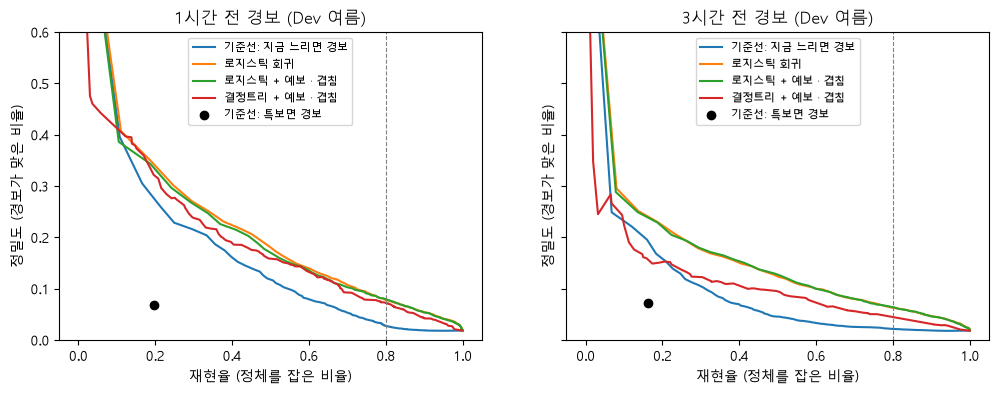

In [13]:
pr = pd.read_csv(TAB / 'alert_dev_pr_curve.csv', encoding='utf-8-sig')
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, h in zip(axes, [1, 3]):
    for name, g in pr[pr['horizon'] == h].groupby('model', sort=False):
        ax.plot(g['recall'], g['precision'], label=name)
    b = am[(am['horizon'] == h) & (am['model'] == '기준선: 특보면 경보')].iloc[0]   # 여름 검증 행
    ax.scatter([b['recall']], [b['precision']], color='k', zorder=5, label='기준선: 특보면 경보')
    ax.axvline(0.8, color='gray', ls='--', lw=.8)
    ax.set_xlabel('재현율 (정체를 잡은 비율)'); ax.set_ylabel('정밀도 (경보가 맞은 비율)')
    ax.set_title(f'{h}시간 전 경보 (Dev 여름)'); ax.set_ylim(0, 0.6); ax.legend(fontsize=8)
fig.savefig(FIG / 'alert_pr_curve.png', dpi=150, bbox_inches='tight')

In [14]:
# 선행 시간 (Dev 여름): 정체가 '시작'된 시각을 3시간 전 / 1시간 전에 잡았나 (겨울로 고른 재현율 80% 임계값)
pd.read_csv(TAB / 'alert_lead_time_dev.csv', encoding='utf-8-sig').round(3)

,model,scope,starts,3시간 전,1시간 전,놓침
0,기준선: 특보면 경보,전체,1267,0.137,0.071,0.792
1,기준선: 특보면 경보,악천후,469,0.371,0.192,0.437
2,기준선: 특보면 경보,08 · 18시 시작 뺌,899,0.160,0.076,0.764
3,기준선: 특보면 경보,악천후 · 08 · 18시 시작 뺌,365,0.395,0.186,0.419
4,기준선: 지금 느리면 경보,전체,1267,0.785,0.096,0.118
5,기준선: 지금 느리면 경보,악천후,469,0.859,0.070,0.070
6,기준선: 지금 느리면 경보,08 · 18시 시작 뺌,899,0.791,0.096,0.113
7,기준선: 지금 느리면 경보,악천후 · 08 · 18시 시작 뺌,365,0.858,0.068,0.074
8,로지스틱 회귀,전체,1267,0.841,0.035,0.125
9,로지스틱 회귀,악천후,469,0.883,0.055,0.062


In [15]:
# 결정트리(3시간 전) 위쪽 규칙: 무엇으로 먼저 가르나
print((TAB / 'alert_tree_rules.txt').read_text(encoding='utf-8')[:2500])

|--- type_ratio_t0 <= 1.02
|   |--- function_type_주간선도로 <= 0.50
|   |   |--- lanes <= 3.08
|   |   |   |--- month_9 <= 0.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- month_9 >  0.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- lanes >  3.08
|   |   |   |--- target_hour_20 <= 0.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- target_hour_20 >  0.50
|   |   |   |   |--- truncated branch of depth 4
|   |--- function_type_주간선도로 >  0.50
|   |   |--- ratio_t0 <= 1.11
|   |   |   |--- n_links <= 8.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- n_links >  8.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- ratio_t0 >  1.11
|   |   |   |--- ratio_t0 <= 1.20
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- ratio_t0 >  1.20
|   |   |   |   |--- truncated branch of depth 4
|--- type_ratio_t0 >  1.02
|   |--- ratio_t0 <= 1.13
|   |   |--- weekday_4 <= 0.50
|   |   |   |--- type_ratio_t

## 9. 경보 모델 정리 (임계값은 Dev 겨울로 고르고 Dev 여름 95일에서 잼, 평일 출퇴근 · 정체 1.9%)

- **같은 경보 수로 비교하면 로지스틱 회귀가 특보 기준선보다 2.3~2.6배 더 잡는다.** 하루 경보 47개(1시간 전)일 때 재현율 50.3% vs 19.6%, 38개(3시간 전)일 때 36.8% vs 16.3%.
- 특보 기준선은 정체의 **80~84%를 놓친다.** 정체 대부분은 특보가 없는 시간에 생기기 때문이다.
- **악천후 시간만 보면** (같은 경보 수) 1시간 전 68% vs 특보 50%, 3시간 전 49% vs 42%. 여름 검증에서는 3시간 전에도 특보보다 조금 낫다.
- **겨울로 고른 임계값을 여름에 쓰면** 재현율이 1시간 전 75% · 3시간 전 86%로, 목표 80% 근처에서 크게 벗어나지 않는다. 대신 헛경보가 하루 118개(1시간 전) · 250개(3시간 전)로 많다. 정체가 드물어 '모두 잡기'의 값이 비싸다.
- **예보 · 겹침 열은 성능을 거의 바꾸지 않았다** (PR-AUC 1시간 전 0.210 → 0.206, 3시간 전 0.146 → 0.146). 예보에서 볼 수 있는 큰 비 · 눈 시간은 전체의 일부이고, 정체 대부분은 날씨와 상관없이 도로와 지금 상태로 설명되기 때문으로 보인다. 그래서 **경보 모델은 예보 없는 로지스틱 회귀(단순한 쪽)**를 그대로 쓴다. 예보는 '악천후 모드를 켤지'를 정하는 12/2 발동 기준에서 쓴다.
- **3시간 전은 1시간 전보다 훨씬 어렵다** (PR-AUC 0.21 → 0.15). A 회귀와 같은 결론이다.
- **헛경보를 세는 단위** (코드 검토 4번): 위 '하루 헛경보'는 도로 · 방향 × 목표 시각 칸 수다. 같은 날 같은 도로를 한 번으로 묶으면 1시간 전 재현율 80% 규칙은 하루 55개 도로(칸 118개), 특보와 같은 경보 수는 24개 도로다. 둘 다 이용자에게 실제로 보낸 알림 수는 아니다.
- **선행 시간의 '시작'**은 '출퇴근 구간에서 처음 관측한 정체'다 (코드 검토 5번). 08 · 18시는 직전 시각의 정체 정답이 없어 이전부터 막혀 있었는지 모른다. 이 두 시각을 빼도 로지스틱 회귀가 3시간 전에 잡은 비율은 84% → 87%로 비슷하다.
- **검증 범위** (코드 검토 6번): 경보의 트리 깊이 · 임계값은 Dev 겨울로 골랐고 Dev 여름은 검증에만 썼다. 다만 정체 정답의 길이 기준(30%)은 학습 시즌 전체(여름 Dev 포함)로 정했으므로, '정체 정의까지 독립 검증'은 아니다. Test에서 한 번 더 확인한다.
- 결정트리는 '같은 유형 도로들의 지금 비율'과 '이 도로의 지금 비율'로 먼저 가른다. 날씨보다 **도로와 지금 상태**가 정체를 더 많이 설명한다.
- **경보 기준 제안**: 1시간 전 로지스틱 회귀(예보 없음). 임계값은 ① 재현율 80% (겨울에서 고른 값, 헛경보 많음) 또는 ② 특보와 같은 경보 수 (하루 약 47개, 특보보다 2.6배 더 잡음) 중에서 12/2 발동 기준과 함께 정한다.
- 한계: Dev 여름 하나로 잰 값이다. Test(2025~26 겨울 · 2026 여름)에서 한 번만 확인한다. 특보 기준선은 '발효 중'만 썼다 (예비특보 열은 학습 기간에 값이 없음).